<a href="https://colab.research.google.com/github/CamilaHenaoIbero/Actividad4-Aprendizaje-No-Supervisado/blob/main/Actividad_4_Aprendizaje_No_Supervisado_ipynb_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

¡Dataset 'dataset_transporte.csv' creado con éxito automáticamente!

Centroides de los grupos encontrados:
[[-1.14160332 -1.02505182  1.24603685]
 [-0.10245158 -0.28268119 -0.2184766 ]
 [ 1.22941896  1.26734998 -1.05877119]]


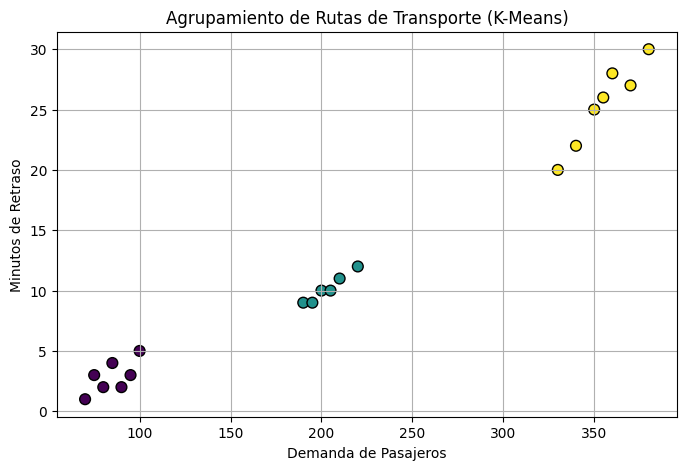


¡Proceso de clustering completado con éxito!


In [1]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# 1. Crear el dataset automáticamente para que no tengas que subir archivos
np.random.seed(42)
datos_simulados = {
    'Demanda_Pasajeros': [350, 80, 200, 380, 95, 210, 340, 70, 190, 360, 85, 220, 330, 90, 205, 370, 75, 195, 355, 100],
    'Minutos_Retraso': [25, 2, 10, 30, 3, 11, 22, 1, 9, 28, 4, 12, 20, 2, 10, 27, 3, 9, 26, 5],
    'Frecuencia_Bus': [4, 15, 8, 3, 14, 8, 5, 18, 9, 4, 16, 7, 5, 15, 8, 3, 17, 9, 4, 13]
}

df = pd.DataFrame(datos_simulados)
df.to_csv('dataset_transporte.csv', index=False)
print("¡Dataset 'dataset_transporte.csv' creado con éxito automáticamente!")

# 2. Cargar los datos recién creados
df = pd.read_csv('dataset_transporte.csv')

# 3. Seleccionar y escalar las variables numéricas
X = df[['Demanda_Pasajeros', 'Minutos_Retraso', 'Frecuencia_Bus']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Definir y entrenar el modelo K-Means (3 grupos)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Grupo'] = kmeans.fit_predict(X_scaled)

# 5. Mostrar los centroides y resultados
print("\nCentroides de los grupos encontrados:")
print(kmeans.cluster_centers_)

# 6. Visualizar los resultados en una gráfica de dispersión
plt.figure(figsize=(8, 5))
plt.scatter(df['Demanda_Pasajeros'], df['Minutos_Retraso'], c=df['Grupo'], cmap='viridis', s=60, edgecolors='k')
plt.title('Agrupamiento de Rutas de Transporte (K-Means)')
plt.xlabel('Demanda de Pasajeros')
plt.ylabel('Minutos de Retraso')
plt.grid(True)
plt.show()

# Guardar los resultados agrupados
df.to_csv('dataset_agrupado_transporte.csv', index=False)
print("\n¡Proceso de clustering completado con éxito!")